# Single-Qubit Gates

Applies one gate to a chosen starting state and shows the gate matrix, the
state before and after, and the final state on the **Bloch sphere**.

| Gate | What it does |
|---|---|
| I | identity: does nothing |
| X, Y, Z | Pauli gates: X and Y flip \|0⟩ ↔ \|1⟩, Z flips the sign of \|1⟩ |
| H | Hadamard: \|0⟩ → \|+⟩, \|1⟩ → \|−⟩ |
| S, T | add a phase to \|1⟩: *i* (90°) and e^{iπ/4} (45°) |
| SDG, TDG | S† and T†: undo S and T (phase −90° and −45°) |
| SX, SXDG | √X and its inverse: two SX gates make one X |
| RX, RY, RZ | rotate the Bloch vector by an angle about the x, y or z axis |
| P | add any phase to \|1⟩: P(90) = S, P(45) = T |
| U | general gate U(θ, φ, λ): any single-qubit gate, e.g. U(90, 0, 180) = H |

Phase gates (Z, S, T, P, RZ) have no visible effect on |0⟩; try them on |+⟩.

**Inputs:** the gate, its angle(s) in degrees (only RX, RY, RZ, P and U ask),
and the initial state (0, 1, +, −).
The second cell saves the circuit diagram as a PNG.

Enter gate (I, X, Y, Z, H, S, SDG, T, TDG, SX, SXDG, RX, RY, RZ, P, U):  RY
Enter angle in degrees:  60
Enter initial state (0, 1, +, -):  0


RY(60) gate matrix:
[[ 0.866+0.j -0.5  +0.j]
 [ 0.5  +0.j  0.866+0.j]]

Initial state |0>:
1.0000|0> + 0.0000|1>

State after RY(60) gate:
0.8660|0> + 0.5000|1>

P(0) = 0.7500
P(1) = 0.2500


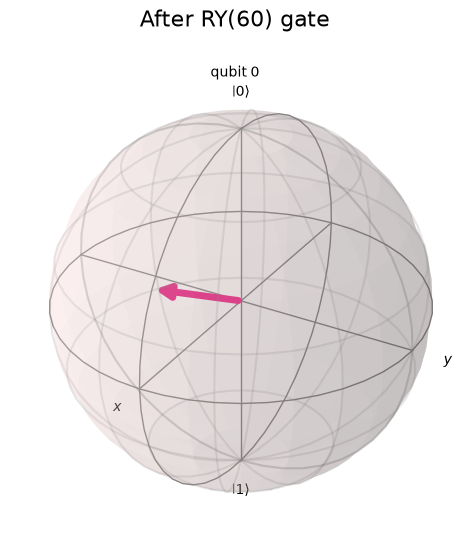

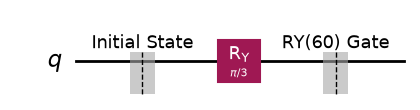

In [1]:
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_bloch_multivector
from IPython.display import display
import numpy as np

# 1. Available single-qubit gates
#    Identity      : I
#    Pauli gates   : X, Y, Z
#    Hadamard      : H
#    Phase gates   : S, SDG (S dagger), T, TDG (T dagger)
#    Square root X : SX, SXDG (SX dagger)
#    With an angle : RX, RY, RZ (rotations), P (phase)
#    General gate  : U (theta, phi, lambda)
fixed_gates = ["I", "X", "Y", "Z", "H", "S", "SDG", "T", "TDG", "SX", "SXDG"]
angle_gates = ["RX", "RY", "RZ", "P"]

# 2. User input
gate = input("Enter gate (I, X, Y, Z, H, S, SDG, T, TDG, SX, SXDG, RX, RY, RZ, P, U): ").strip().upper()

if gate not in fixed_gates + angle_gates + ["U"]:
    raise ValueError("Enter one of the listed gates.")

angles_deg = []

if gate in angle_gates:
    angles_deg = [float(input("Enter angle in degrees: "))]
elif gate == "U":
    angles_deg = [float(input(f"Enter {name} in degrees: ")) for name in ["theta", "phi", "lambda"]]

angles = [np.radians(a) for a in angles_deg]

start = input("Enter initial state (0, 1, +, -): ").strip()

if start not in ["0", "1", "+", "-"]:
    raise ValueError("Enter one of 0, 1, +, -.")

# Gate name with its angles, e.g. RY(60)
gate_label = gate
if angles_deg:
    gate_label = f"{gate}({', '.join(f'{a:g}' for a in angles_deg)})"

# 3. Apply the chosen gate to a qubit
def apply_gate(circuit, qubit):
    if gate == "I":
        circuit.id(qubit)
    else:
        getattr(circuit, gate.lower())(*angles, qubit)

# 4. Format complex amplitudes
def format_amplitude(value):
    real = value.real
    imag = value.imag

    if abs(imag) < 1e-8:
        return f"{real:.4f}"

    if abs(real) < 1e-8:
        return f"{imag:.4f}j"

    sign = "+" if imag >= 0 else "-"
    return f"{real:.4f} {sign} {abs(imag):.4f}j"

# 5. Create circuit
q = QuantumRegister(1, 'q')
qc = QuantumCircuit(q)

# 6. Prepare initial state
if start == "1":
    qc.x(q[0])
elif start == "+":
    qc.h(q[0])
elif start == "-":
    qc.x(q[0])
    qc.h(q[0])

qc.barrier(label="Initial State")

sv_before = Statevector(qc)

# 7. Apply the chosen gate
apply_gate(qc, q[0])
qc.barrier(label=f"{gate_label} Gate")

sv_after = Statevector(qc)

# 8. Gate matrix
gate_circuit = QuantumCircuit(1)
apply_gate(gate_circuit, 0)

print(f"{gate_label} gate matrix:")
print(np.round(Operator(gate_circuit).data, 4))

# 9. State before and after
print(f"\nInitial state |{start}>:")
print(f"{format_amplitude(sv_before.data[0])}|0> + {format_amplitude(sv_before.data[1])}|1>")

print(f"\nState after {gate_label} gate:")
print(f"{format_amplitude(sv_after.data[0])}|0> + {format_amplitude(sv_after.data[1])}|1>")

print(f"\nP(0) = {abs(sv_after.data[0])**2:.4f}")
print(f"P(1) = {abs(sv_after.data[1])**2:.4f}")

# 10. Bloch sphere after the gate
display(plot_bloch_multivector(sv_after, title=f"After {gate_label} gate"))

# 11. Draw circuit
qc.draw(output='mpl', fold=-1, scale=1.0)

In [2]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("0_2_SingleQubitGates.png", dpi=300, bbox_inches="tight")